# 2.11d — Optimisation ADMM pour le Lasso

[Source Python](2.11d-Optimisation-ADMM-From-Scratch.ipynb)

**Objectifs** : décomposer le Lasso, suivre les résidus et comparer ADMM à une descente de coordonnées, scikit-learn et CVXPY. **Prérequis** : Lasso, systèmes linéaires et proximal L1. **Durée indicative** : 90 minutes.

Nous minimisons `½‖Xβ−y‖² + λ‖z‖₁` sous `β=z`. MathNet effectue les calculs C# ; les données et les références utilisent NumPy, scikit-learn et CVXPY via Python.NET.

In [1]:
#r "nuget: MathNet.Numerics, 5.0.0"
#r "nuget: PythonNet, 3.0.5"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Diagnostics;
using System.Text;
using System.Text.Json;
using MathNet.Numerics.LinearAlgebra;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (string.IsNullOrWhiteSpace(library))
        throw new InvalidOperationException("Définir PYTHONNET_PYDLL vers CPython et installer NumPy, scikit-learn et CVXPY.");
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
string PythonResult(string source)
{
    using (Py.GIL())
    using (var scope = Py.CreateScope())
    {
        scope.Exec(source);
        return scope.Get("result").As<string>();
    }
}
var V = Vector<double>.Build;
var Mat = Matrix<double>.Build;
Vector<double> ArrayVector(JsonElement array) => V.DenseOfEnumerable(array.EnumerateArray().Select(x => x.GetDouble()));
Matrix<double> ArrayMatrix(JsonElement array) => Mat.DenseOfRowArrays(array.EnumerateArray().Select(row => row.EnumerateArray().Select(x => x.GetDouble()).ToArray()).ToArray());
Vector<double> Shrink(Vector<double> x, double threshold) => x.Map(v => Math.Sign(v) * Math.Max(Math.Abs(v) - threshold, 0.0));
double Objective(Matrix<double> a, Vector<double> b, Vector<double> x, double lambda)
{
    var residual = a * x - b;
    return 0.5 * residual.DotProduct(residual) + lambda * x.L1Norm();
}
Console.WriteLine("MathNet et Python.NET initialisés ; références Python chargées au besoin.");

Installed Packages MathNet.Numerics, 5.0.0 PythonNet, 3.0.5

MathNet et Python.NET initialisés ; références Python chargées au besoin.


## Données corrélées et seuil de régularisation

Le générateur NumPy garde `n=100`, `p=50`, `k=5`, corrélation AR(1) 0,95, SNR 4 et graine 20260914. Le seuil brut est `λmax=max|Xᵀy|` ; scikit-learn prend `α=λ/n`.

In [2]:
var input = JsonDocument.Parse(PythonResult(@"
import json, time, numpy as np, cvxpy as cp
from sklearn.linear_model import Lasso
n,p,k=100,50,5
rng=np.random.default_rng(20260914)
idx=np.arange(p); Sigma=0.95**np.abs(idx[:,None]-idx[None,:])
L=np.linalg.cholesky(Sigma); X=rng.standard_normal((n,p))@L.T
support=np.sort(rng.choice(p,size=k,replace=False)); truth=np.zeros(p); truth[support]=rng.standard_normal(k)
signal=X@truth; sigma=np.linalg.norm(signal)/np.sqrt(n)/4.0
y=signal+rng.standard_normal(n)*sigma
lam=.5*np.max(np.abs(X.T@y))
start=time.perf_counter()
sk=Lasso(alpha=lam/n,max_iter=2000,tol=1e-6,fit_intercept=False).fit(X,y)
sk_seconds=time.perf_counter()-start
v=cp.Variable(p); prob=cp.Problem(cp.Minimize(.5*cp.sum_squares(X@v-y)+lam*cp.norm(v,1)))
start=time.perf_counter()
try:
    prob.solve(solver=cp.CLARABEL,tol_gap_abs=1e-8,tol_gap_rel=1e-8,tol_feas=1e-8,verbose=False)
except Exception:
    prob.solve(solver=cp.SCS,eps=1e-8,verbose=False)
cvx_seconds=time.perf_counter()-start
if prob.status != 'optimal': raise RuntimeError('CVXPY: '+str(prob.status))
result=json.dumps(dict(X=X.tolist(),y=y.tolist(),truth=truth.tolist(),support=support.tolist(),lam=float(lam),sklearn=sk.coef_.tolist(),cvx=np.asarray(v.value).ravel().tolist(),objective=prob.value,solver=prob.solver_stats.solver_name,sk_seconds=sk_seconds,cvx_seconds=cvx_seconds,condition=float(np.linalg.cond(X))))")).RootElement;
var x = ArrayMatrix(input.GetProperty("X"));
var y = ArrayVector(input.GetProperty("y"));
var truth = ArrayVector(input.GetProperty("truth"));
var lambda = input.GetProperty("lam").GetDouble();
var sklearn = ArrayVector(input.GetProperty("sklearn"));
var cvx = ArrayVector(input.GetProperty("cvx"));
var optimum = input.GetProperty("objective").GetDouble();
Console.WriteLine($"n={x.RowCount}, p={x.ColumnCount}, support={string.Join(",",input.GetProperty("support").EnumerateArray().Select(i => i.GetInt32()))}, condition={input.GetProperty("condition").GetDouble():F2}");
Console.WriteLine($"λmax={2*lambda:F4}, λ={lambda:F4}, α={lambda/x.RowCount:F4}");
Console.WriteLine($"CVXPY {input.GetProperty("solver").GetString()}, objectif={optimum:F8}");

n=100, p=50, support=2,13,24,44,47, condition=81.83


λmax=115.2719, λ=57.6360, α=0.5764


CVXPY CLARABEL, objectif=158.89045512


## ADMM et descente de coordonnées

Le système `(XᵀX+ρI)β=Xᵀy+ρ(z−u)` est factorisé une fois par valeur de ρ. La variable `z` porte la parcimonie ; les résidus primal et dual sont tous deux nécessaires à l'arrêt.

In [3]:
record AdmmResult(Vector<double> Beta, Vector<double> Z, double[] ObjectiveBeta, double[] ObjectiveZ, double[] Primal, double[] Dual, bool Converged);
AdmmResult Admm(Matrix<double> a, Vector<double> b, double lam, double rho, int maxIter = 500, double epsAbs = 1e-4, double epsRel = 1e-4)
{
    int p = a.ColumnCount;
    var xt = a.Transpose();
    var factor = (xt * a + rho * Mat.DenseIdentity(p)).Cholesky();
    var xty = xt * b;
    var beta = V.Dense(p);
    var z = V.Dense(p);
    var u = V.Dense(p);
    var objectivesBeta = new List<double>();
    var objectivesZ = new List<double>();
    var primal = new List<double>();
    var dual = new List<double>();
    bool converged = false;
    for (int iteration = 0; iteration < maxIter; iteration++)
    {
        var previousZ = z;
        beta = factor.Solve(xty + rho * (z - u));
        z = Shrink(beta + u, lam / rho);
        u = u + beta - z;
        double rp = (beta - z).L2Norm();
        double rd = rho * (z - previousZ).L2Norm();
        double toleranceP = Math.Sqrt(p) * epsAbs + epsRel * Math.Max(beta.L2Norm(), z.L2Norm());
        double toleranceD = Math.Sqrt(p) * epsAbs + epsRel * rho * u.L2Norm();
        objectivesBeta.Add(Objective(a, b, beta, lam));
        objectivesZ.Add(Objective(a, b, z, lam));
        primal.Add(rp);
        dual.Add(rd);
        if (rp < toleranceP && rd < toleranceD)
        {
            converged = true;
            break;
        }
    }
    return new AdmmResult(beta, z, objectivesBeta.ToArray(), objectivesZ.ToArray(), primal.ToArray(), dual.ToArray(), converged);
}
(Vector<double> beta, int iterations) CoordinateDescent(Matrix<double> a, Vector<double> b, double lam, int maxIter = 2000, double tol = 1e-6)
{
    var beta = V.Dense(a.ColumnCount);
    for (int iteration = 1; iteration <= maxIter; iteration++)
    {
        var previous = beta.Clone();
        for (int j = 0; j < a.ColumnCount; j++)
        {
            var column = a.Column(j);
            double value = column.DotProduct(b - a * beta + column * beta[j]);
            beta[j] = Math.Sign(value) * Math.Max(Math.Abs(value) - lam, 0) / column.DotProduct(column);
        }
        if ((beta - previous).L2Norm() < tol) return (beta, iteration);
    }
    return (beta, maxIter);
}
Console.WriteLine("ADMM et descente de coordonnées C# définis.");

ADMM et descente de coordonnées C# définis.


À `ρ=20`, on compare les estimations sur la même instance. Les deux évaluations `f(β)` et `f(z)` sont séparément faisables ; mélanger la perte en β et la pénalité en z ne donnerait pas nécessairement une borne supérieure de l'optimum.

In [4]:
var watch = Stopwatch.StartNew();
var admm = Admm(x, y, lambda, 20.0);
watch.Stop(); double admmSeconds = watch.Elapsed.TotalSeconds;
watch.Restart();
var cd = CoordinateDescent(x, y, lambda);
watch.Stop(); double cdSeconds = watch.Elapsed.TotalSeconds;
void Report(string name, Vector<double> value, int iterations, bool converged = true)
{
    var active = Enumerable.Range(0,value.Count).Where(i => Math.Abs(value[i]) > 1e-6).ToHashSet();
    var actual = Enumerable.Range(0,value.Count).Where(i => truth[i] != 0).ToHashSet();
    int tp = active.Intersect(actual).Count();
    double precision = tp / (double)Math.Max(active.Count, 1);
    double recall = tp / (double)actual.Count;
    double f1 = precision + recall == 0 ? 0 : 2 * precision * recall / (precision + recall);
    Console.WriteLine($"{name,-12} écart={(value-cvx).L2Norm():E3}, support={active.Count}, FP={active.Count-tp}, précision={precision:P1}, rappel={recall:P1}, F1={f1:P1}, it={(iterations > 0 ? iterations.ToString() : "non mesurées")}, convergé={(iterations > 0 ? converged.ToString() : "non mesuré")}");
}
Report("ADMM z", admm.Z, admm.Primal.Length, admm.Converged);
Report("Coordonnée", cd.beta, cd.iterations);
Report("sklearn", sklearn, 0);
Console.WriteLine($"Temps (s) : ADMM={admmSeconds:F4}, CD={cdSeconds:F4}, sklearn={input.GetProperty("sk_seconds").GetDouble():F4}, CVXPY={input.GetProperty("cvx_seconds").GetDouble():F4}");
Console.WriteLine($"ADMM β dense : {admm.Beta.Count(v => Math.Abs(v)>1e-6)} composantes ; résidu primal={admm.Primal.Last():E3}");

ADMM z       écart=2.078E-003, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=178, convergé=True


Coordonnée   écart=1.004E-007, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=14, convergé=True


sklearn      écart=6.565E-008, support=2, FP=0, précision=100.0 %, rappel=40.0 %, F1=57.1 %, it=non mesurées, convergé=non mesuré


Temps (s) : ADMM=0.0867, CD=0.1388, sklearn=0.0014, CVXPY=0.0221


ADMM β dense : 48 composantes ; résidu primal=7.613E-004


### Exercice 1 — Trajectoires

Balayer ρ=0,01, 0,1, 1, 10, 100 avec 500 itérations et tracer les deux objectifs, les résidus et le nombre d’itérations.

In [5]:
AdmmResult[] ExerciceTrajectoires(Matrix<double> matrix, Vector<double> target, double lam)
{
    // TODO : exécuter ADMM pour 0,01, 0,1, 1, 10, 100 et tracer objectifs et résidus.
    return null;
}
var answer = ExerciceTrajectoires(x, y, lambda);
if (answer == null)
    Console.WriteLine("Exercice 1 à compléter.");
else
{
    var rhos = new[]{0.01,0.1,1.0,10.0,100.0};
    bool ok = answer.Length == rhos.Length;
    for (int i = 0; ok && i < rhos.Length; i++)
    {
        var expected = Admm(x,y,lambda,rhos[i],500);
        var actual = answer[i];
        ok = actual != null && actual.Primal.Length == expected.Primal.Length &&
             actual.Dual.Length == expected.Dual.Length && actual.ObjectiveBeta.Length == expected.ObjectiveBeta.Length &&
             actual.ObjectiveZ.Length == expected.ObjectiveZ.Length && (actual.Z-expected.Z).L2Norm() < 1e-8 &&
             actual.Converged == expected.Converged &&
             actual.Primal.Zip(expected.Primal,(a,b) => Math.Abs(a-b) < 1e-8).All(v => v) &&
             actual.Dual.Zip(expected.Dual,(a,b) => Math.Abs(a-b) < 1e-8).All(v => v) &&
             actual.ObjectiveBeta.Zip(expected.ObjectiveBeta,(a,b) => Math.Abs(a-b) < 1e-8).All(v => v) &&
             actual.ObjectiveZ.Zip(expected.ObjectiveZ,(a,b) => Math.Abs(a-b) < 1e-8).All(v => v);
    }
    Console.WriteLine(ok ? "Exercice 1 : calculs corrects ; examiner les tracés" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


## Objectifs et résidus

La figure suit les objectifs de β et z par rapport à la référence CVXPY et les résidus primal/dual en échelle logarithmique.

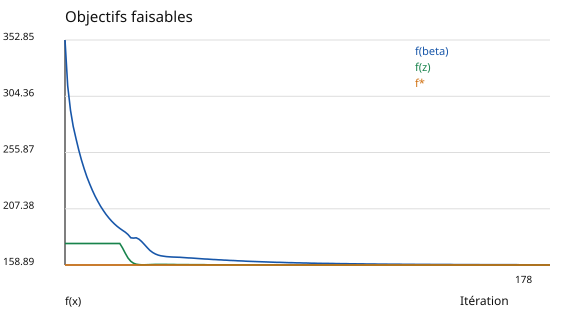

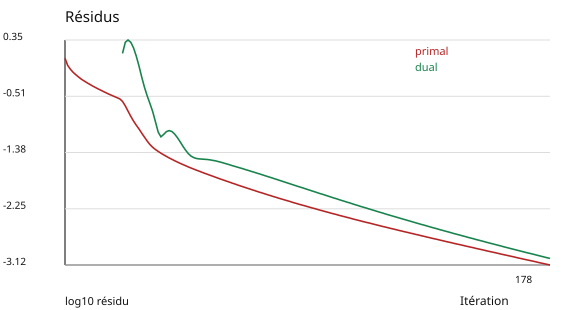

In [6]:
// Émet deux panneaux SVG opaques sous le MIME reconnu par GitHub.
record GraphSvg(string Value);
Formatter.Register<GraphSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
string Plot(string title, string yLabel, (string label, double[] values, string color)[] series, bool logY = false)
{
    const int width = 570, height = 310, left = 65, right = 20, top = 40, bottom = 45;
    var all = series.SelectMany(s => s.values).Where(v => double.IsFinite(v) && (!logY || v > 0)).Select(v => logY ? Math.Log10(v) : v).ToArray();
    double ymin = all.Min(), ymax = all.Max();
    if (ymax <= ymin) ymax = ymin + 1;
    int count = series.Max(s => s.values.Length);
    var svg = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif' fill='#111'><text x='65' y='22' font-size='15'>{title}</text><text x='460' y='305' font-size='12'>Itération</text><text x='65' y='305' font-size='11'>{yLabel}</text><line x1='{left}' y1='{top}' x2='{left}' y2='{height-bottom}' stroke='black'/><line x1='{left}' y1='{height-bottom}' x2='{width-right}' y2='{height-bottom}' stroke='black'/>");
    for (int tick = 0; tick <= 4; tick++)
    {
        double value = ymin + (ymax - ymin) * tick / 4;
        double y = height - bottom - (height - top - bottom) * tick / 4.0;
        svg.Append($"<text x='3' y='{y:0.0}' font-size='10'>{value:0.##}</text><line x1='{left}' y1='{y:0.0}' x2='{width-right}' y2='{y:0.0}' stroke='#ddd'/>");
    }
    int legend = 0;
    foreach (var item in series)
    {
        var points = new StringBuilder();
        for (int i = 0; i < item.values.Length; i++)
        {
            if (!double.IsFinite(item.values[i]) || (logY && item.values[i] <= 0))
            {
                if (points.Length > 0)
                {
                    svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/>");
                    points.Clear();
                }
                continue;
            }
            double value = logY ? Math.Log10(item.values[i]) : item.values[i];
            double px = left + (width-left-right) * i / (double)Math.Max(1, count-1);
            double py = height-bottom - (height-top-bottom) * (value-ymin)/(ymax-ymin);
            points.Append($"{px:0.0},{py:0.0} ");
        }
        svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/><text x='{width-155}' y='{55+legend*16}' fill='{item.color}' font-size='11'>{item.label}</text>");
        legend++;
    }
    svg.Append($"<text x='{width-55}' y='{height-27}' font-size='10'>{count}</text></g></svg>");
    return svg.ToString();
}
display(new GraphSvg(Plot("Objectifs faisables", "f(x)", new[]{("f(beta)",admm.ObjectiveBeta,"#1756a9"),("f(z)",admm.ObjectiveZ,"#18834c"),("f*",Enumerable.Repeat(optimum,admm.Primal.Length).ToArray(),"#d07010")})), "image/svg+xml");
display(new GraphSvg(Plot("Résidus", "log10 résidu", new[]{("primal",admm.Primal,"#b52525"),("dual",admm.Dual,"#18834c")},true)), "image/svg+xml");

### Exercice 2 — Design colinéaire

Construire un design 80×10 dont la deuxième colonne diffère de la première par un bruit 0,001 ; λ=0,5 et ρ=0,01, 0,1, 1, 10.

In [7]:
(Matrix<double> design, Vector<double> target, AdmmResult[] results) ExerciceColinearite()
{
    // TODO : générer le problème 80×10 et exécuter ADMM pour les quatre rho indiqués.
    return (null, null, null);
}
var answer = ExerciceColinearite();
if (answer.design == null || answer.target == null || answer.results == null)
    Console.WriteLine("Exercice 2 à compléter.");
else
{
    var rhos = new[]{0.01,0.1,1.0,10.0};
    bool ok = answer.design.RowCount == 80 && answer.design.ColumnCount == 10 && answer.target.Count == 80 && answer.results.Length == 4;
    if (ok)
    {
        double ratio = (answer.design.Column(1)-answer.design.Column(0)).L2Norm() / answer.design.Column(0).L2Norm();
        ok = ratio > 0 && ratio < 0.01;
    }
    for (int i = 0; ok && i < rhos.Length; i++)
    {
        var expected = Admm(answer.design,answer.target,0.5,rhos[i],500);
        var actual = answer.results[i];
        ok = actual != null && actual.Primal.Length == expected.Primal.Length &&
             (actual.Z-expected.Z).L2Norm() < 1e-8 && actual.Converged == expected.Converged;
    }
    Console.WriteLine(ok ? "Exercice 2 : calculs corrects ; examiner les supports" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


## Influence de ρ

On conserve les sept valeurs et le plafond de 500 itérations du source. Un arrêt par épuisement du budget ne certifie pas l'optimum ; ρ modifie le chemin et la convergence, pas l'objectif cible.

In [8]:
foreach (double rho in new[]{0.5, 1.0, 5.0, 20.0, 50.0, 100.0, 500.0})
{
    var result = Admm(x, y, lambda, rho, 500);
    double rp = result.Primal.Last();
    double rd = result.Dual.Last();
    Console.WriteLine($"ρ={rho,6:F1}, it={result.Primal.Length,3}, convergé={result.Converged,-5}, écart={(result.Z-cvx).L2Norm():E3}, f(z)={result.ObjectiveZ.Last():F4}, support={result.Z.Count(v => Math.Abs(v)>1e-6)}, rp={rp:E3}, rd={rd:E3}, ratio={(rd>0 ? rp/rd : double.PositiveInfinity):F2}");
}

ρ=   0.5, it=500, convergé=False, écart=6.567E-001, f(z)=177.4140, support=0, rp=4.022E-001, rd=0.000E+000, ratio=Infinity


ρ=   1.0, it=500, convergé=False, écart=1.817E-001, f(z)=160.3060, support=2, rp=1.193E-001, rd=1.794E-003, ratio=66.49


ρ=   5.0, it=500, convergé=False, écart=7.013E-003, f(z)=158.8935, support=2, rp=2.348E-003, rd=2.269E-004, ratio=10.35


ρ=  20.0, it=178, convergé=True , écart=2.078E-003, f(z)=158.8907, support=2, rp=7.613E-004, rd=9.614E-004, ratio=0.79


ρ=  50.0, it= 74, convergé=True , écart=2.015E-003, f(z)=158.8907, support=2, rp=7.625E-004, rd=5.803E-003, ratio=0.13


ρ= 100.0, it= 40, convergé=True , écart=1.924E-003, f(z)=158.8906, support=2, rp=7.490E-004, rd=1.027E-002, ratio=0.07


ρ= 500.0, it= 90, convergé=True , écart=1.700E-004, f(z)=158.8905, support=2, rp=5.282E-005, rd=2.062E-002, ratio=0.00


### Exercice 3 — Ridge

Modifier le proximal en z = ρ/(ρ+2λ)·(β+u), puis comparer la solution au système ridge.

In [9]:
Vector<double> ExerciceRidge(Matrix<double> matrix, Vector<double> target, double lam, double rho)
{
    // TODO : implémenter ADMM avec proximal ridge, puis renvoyer z.
    return null;
}
var fixtureA = Mat.DenseOfArray(new double[,] {{2,0},{0,1}});
var fixtureB = V.DenseOfArray(new[]{4.0,-3.0});
var answer = ExerciceRidge(fixtureA, fixtureB, 0.5, 2.0);
if (answer == null)
    Console.WriteLine("Exercice 3 à compléter.");
else
{
    var expected = V.DenseOfArray(new[]{8.0/5.0,-3.0/2.0});
    bool ok = answer.Count == 2 && (answer-expected).L2Norm() < 1e-3;
    Console.WriteLine(ok ? "Exercice 3 : correct" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


## À retenir

ADMM sépare l'ajustement et la parcimonie ; ses deux résidus contrôlent la faisabilité et la stationnarité. Le choix de ρ agit sur la vitesse, tandis que λ définit le problème.

## Vérifiez votre compréhension

Pourquoi évaluer le support sur z ?

<details><summary>Réponse</summary>Le proximal L1 annule des composantes de z, tandis que le sous-problème quadratique β reste dense à tolérance finie.</details>

## Pour aller plus loin

Comparer à [ISTA et FISTA](2.11b-Proximal-Operators-From-Scratch.ipynb).